# Praktikum 2
Klasifikasi Naive Bayes dengan Data Dummy

**Naive Bayes** adalah klasifikasi probabilistik berbasis Teorema Bayes dengan asumsi **independensi antar fitur**:

$$P(y \mid X) \propto P(y)\prod_{i} P(x_i \mid y)$$

Pada percobaan ini kita bangkitkan data dummy dengan `make_classification`, lalu bandingkan **MultinomialNB** (untuk fitur diskrit/cacah) dengan **GaussianNB** (untuk fitur kontinu).

### Langkah 1 - Buat Dataset Dummy

In [1]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2,
                           n_redundant=0, n_repeated=0, shuffle=False, random_state=42)

# Absolutekan nilai X
X = np.absolute(X)

# Bulatkan 2 angka di belakang koma, lalu kalikan 100 agar menjadi bilangan bulat
X = np.round(X, 2) * 100

# Ubah ke bentuk integer
X = X.astype(int)

print(X)
print(y)

[[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]
 [ 50 142]
 [206 110]
 [115  84]
 [124  66]
 [150  85]
 [ 16  73]
 [ 46 113]
 [ 26  80]
 [ 18 114]
 [211 154]
 [ 53  66]
 [ 93 109]
 [175 172]
 [ 80  85]
 [111 125]
 [115 105]
 [ 66  92]
 [160  85]
 [ 53 106]
 [122  85]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Parameter `make_classification`:

* `n_samples` — jumlah sampel
* `n_features` — jumlah fitur
* `n_classes` — jumlah kelas
* `n_informative` — fitur yang benar-benar berkorelasi dengan kelas
* `n_redundant` — fitur yang tidak berkorelasi dengan kelas
* `n_repeated` — fitur yang diulang

> **Penyesuaian:** `random_state=42` ditambahkan pada `make_classification` agar data dummy dan hasilnya **reproduksibel** (pada modul tidak diset sehingga hasil berubah tiap eksekusi).

### Langkah 2 (Opsional) - Membuat Data Frame
Agar lebih mudah dibaca, data dummy diubah menjadi DataFrame.

In [2]:
import pandas as pd

# Reshape label y menjadi 2D agar bisa digabung dengan fitur
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

df.head()

,Fitur 1,Fitur 2,Label
0,112,139,0
1,179,210,0
2,83,71,0
3,182,265,0
4,105,78,0


### Langkah 3 (Opsional) - Labeling
Label masih berupa angka (0/1); ubah ke bentuk kategorikal agar mudah dibaca.

In [3]:
# Definisikan nama label
labels = {1: 'Kelas A', 0: 'Kelas B'}

# Copy Data Frame untuk label yang mudah dibaca
df_label = df.copy()
df_label['Label'] = df_label['Label'].map(labels)

df_label.head()

,Fitur 1,Fitur 2,Label
0,112,139,Kelas B
1,179,210,Kelas B
2,83,71,Kelas B
3,182,265,Kelas B
4,105,78,Kelas B


### Langkah 4 - Visualisasi Data

> **Penyesuaian:** `groupby(['Label'])` pada pandas 3.0 menghasilkan kunci berupa *tuple*, sehingga `get_group('Kelas A')` gagal. Di sini dipakai `groupby('Label')` (tanpa list).

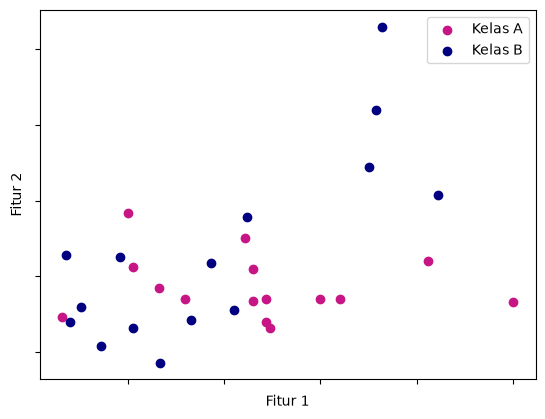

In [4]:
import matplotlib.pyplot as plt

colors = {'class_a': 'MediumVioletRed', 'class_b': 'Navy'}

gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

### Langkah 5 - Model Multinomial Naive Bayes
Secara teori **MultinomialNB** dipakai untuk fitur diskrit (mis. jumlah kata pada teks). Di sini kita coba pada data cacah **hanya sebagai pembelajaran**.

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model (label y harus 1D)
mnb.fit(X_train, y_train)

# Prediksi & evaluasi data training
acc_train = accuracy_score(y_train, mnb.predict(X_train))
# Prediksi & evaluasi data testing
acc_test = accuracy_score(y_test, mnb.predict(X_test))

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.8095238095238095
Hasil akurasi data test: 0.3333333333333333


### Langkah 6 - Model Gaussian Naive Bayes
**GaussianNB** mengasumsikan tiap fitur berdistribusi normal — lebih cocok untuk data kontinu.

In [6]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Gunakan split yang sama
gnb.fit(X_train, y_train)

acc_train_gnb = accuracy_score(y_train, gnb.predict(X_train))
acc_test_gnb = accuracy_score(y_test, gnb.predict(X_test))

print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.4444444444444444


### Kesimpulan

* Dengan `random_state=42`, **MultinomialNB** memberi akurasi latih **0,810** dan uji **0,333**, sedangkan **GaussianNB** memberi akurasi latih **0,857** dan uji **0,444**.
* Kedua model **overfitting**: akurasi latih tinggi tetapi akurasi uji rendah, karena data sangat kecil (30 sampel; uji hanya 9 sampel — satu kesalahan mengubah akurasi ≈ 11%).
* Secara **teoretis**, `GaussianNB` lebih tepat untuk fitur kontinu, sedangkan `MultinomialNB` untuk fitur cacah/diskrit (seperti frekuensi kata). Pada data dummy yang sudah dibulatkan dan dikalikan 100 ini, keduanya bukan pilihan ideal.
* > **Catatan:** angka pada modul (Multinomial 0,619/0,778; Gaussian 0,667/0,556) berbeda karena `make_classification` menghasilkan data acak berbeda antar versi scikit-learn dan tanpa `random_state`. Di sini `random_state=42` ditambahkan agar hasil dapat direproduksi.
* Percobaan ini menegaskan pentingnya memilih varian Naive Bayes sesuai **jenis fitur**, bukan sekadar mengejar akurasi pada data sintetis yang sangat kecil.